# An Interpretable Multi-Modal Spam Detection Framework Using Explainable AI and Machine Learning

**Research notebook** — end-to-end walkthrough of the framework: datasets, methodology, results and explainability analysis.

## Abstract

Scam messages arrive through more than one channel, and modern classifiers that catch them are
usually opaque. This project builds a **multi-modal** (SMS + Email) spam detector that pairs a
**hybrid soft-voting ensemble** — Logistic Regression, Random Forest and XGBoost, weighted by
cross-validated F1 — with an **Explainable-AI layer**: LIME explains every prediction of the full
ensemble at word level, while exact TreeSHAP explains the XGBoost component locally (waterfall)
and globally (beeswarm). On held-out test sets the ensemble reaches
**98.55% accuracy / 0.9941 ROC-AUC on SMS** (UCI SMS Spam
Collection) and **98.25% accuracy / 0.9983 ROC-AUC on
Email** (Enron-Spam). Beyond accuracy, the XAI layer surfaces *why* each verdict was reached —
and even exposes a dataset bias (the token `enron` acting as a ham shortcut), demonstrating why
transparency matters.

**Contents** — 1. Setup · 2. Datasets & EDA · 3. Methodology · 4. Results · 5. Explainability analysis · 6. Discussion & conclusions


## 1. Setup

All reusable logic lives in the `src/` package; this notebook drives it. Artefacts (trained models, metrics, figures) were produced by `python -m src.train`.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook lives in notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import FIGURES_DIR, MODELS_DIR, REPORTS_DIR
from src.data_loader import load_processed
from src.models import SpamDetector

metrics = json.loads((REPORTS_DIR / "metrics.json").read_text())
detectors = {m: SpamDetector.load(MODELS_DIR / f"{m}_detector.joblib") for m in ("sms", "email")}
print("Loaded artefacts generated at", metrics["generated_at"])

Loaded artefacts generated at 2026-08-20T06:58:35+00:00


## 2. Datasets & exploratory analysis

Two public research corpora, one per modality:

| Modality | Corpus | Citation |
|---|---|---|
| SMS | UCI **SMS Spam Collection** | Almeida & Gómez Hidalgo (2011) |
| Email | **Enron-Spam** (subject + body, stratified 12k subsample) | Metsis, Androutsopoulos & Paliouras (2006) |

Both are cleaned identically (drop empties/duplicates); the e-mail corpus is capped at 12 000
messages to keep the pipeline laptop-friendly (configurable in `src/config.py`).

In [2]:
summary = []
for m in ("sms", "email"):
    df = load_processed(m)
    wc = df["text"].str.split().str.len()
    summary.append({
        "modality": m.upper(), "messages": len(df),
        "spam": int((df.label == "spam").sum()), "ham": int((df.label == "ham").sum()),
        "spam share": f"{(df.label == 'spam').mean():.1%}",
        "median words": int(wc.median()), "max words": int(wc.max()),
    })
pd.DataFrame(summary)

,modality,messages,spam,ham,spam share,median words,max words
0,SMS,5158,642,4516,12.4%,12,171
1,EMAIL,12000,5792,6208,48.3%,155,2682


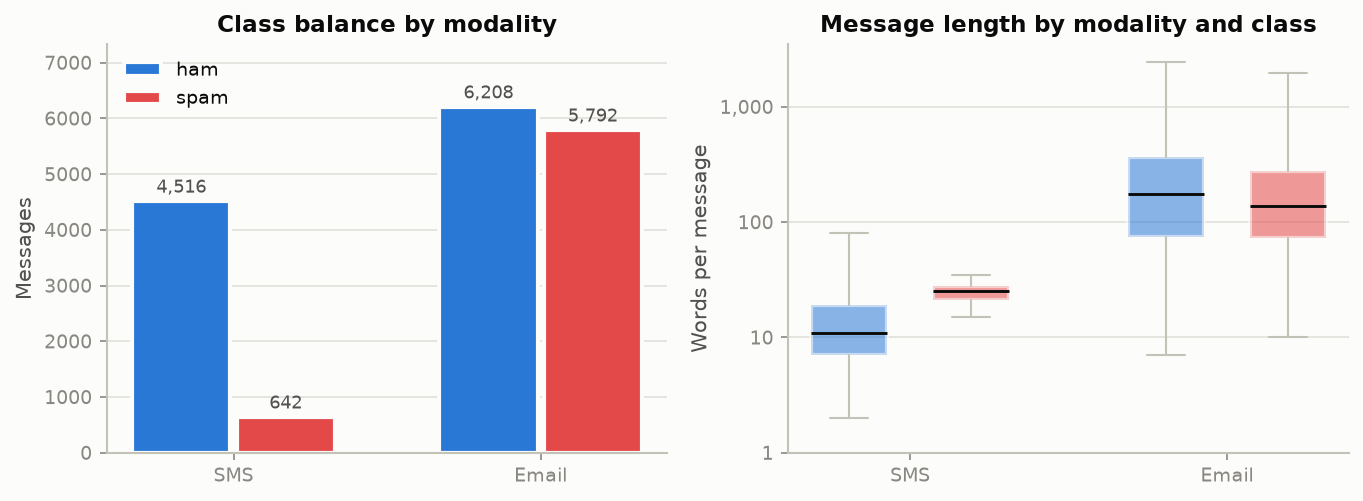

In [3]:
display(Image(filename=str(FIGURES_DIR / "dataset_overview.png"), width=880))

The class-imbalance difference is a key experimental property: SMS is highly imbalanced (≈12% spam) while Enron e-mail is nearly balanced — which is why models are trained per-modality with class weighting (`class_weight='balanced'`, `scale_pos_weight`).

### Which words separate spam from ham?

A quick corpus-level look (before any model): for every token, compare its frequency in spam vs
ham messages. The placeholder tokens produced by normalisation — `httpaddr` (URL), `numbr`
(number), `moneysymb` (money) — already dominate, confirming the intuition that *structure*, not
just vocabulary, signals spam.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from src.preprocessing import normalize_text

def discriminative_tokens(df, top=10):
    cv = CountVectorizer(preprocessor=normalize_text, binary=True, min_df=8)
    X = cv.fit_transform(df["text"])
    y = (df["label"] == "spam").to_numpy(int)
    p_spam = np.asarray(X[y == 1].mean(axis=0)).ravel() + 1e-4   # P(token | spam)
    p_ham = np.asarray(X[y == 0].mean(axis=0)).ravel() + 1e-4    # P(token | ham)
    lo = np.log(p_spam / p_ham)
    toks = cv.get_feature_names_out()
    spam_top = [(toks[i], f"{lo[i]:+.2f}") for i in np.argsort(-lo)[:top]]
    ham_top = [(toks[i], f"{lo[i]:+.2f}") for i in np.argsort(lo)[:top]]
    return pd.DataFrame({"spam-indicative": [t for t, _ in spam_top],
                         "log-ratio": [v for _, v in spam_top],
                         "ham-indicative": [t for t, _ in ham_top],
                         "log-ratio ": [v for _, v in ham_top]})

print("SMS"); display(discriminative_tokens(load_processed("sms")))
print("Email"); display(discriminative_tokens(load_processed("email")))

SMS


,spam-indicative,log-ratio,ham-indicative,log-ratio
0,claim,+7.26,lt,-6.21
1,prize,+7.00,gt,-6.21
2,ppm,+6.46,he,-5.89
3,guaranteed,+6.46,lor,-5.75
4,cs,+6.33,she,-5.46
5,phonenumbr,+6.30,later,-5.37
6,awarded,+6.18,ask,-5.21
7,pobox,+6.18,doing,-5.21
8,tone,+6.18,lol,-5.11
9,ringtone,+5.97,cos,-5.09


Email


,spam-indicative,log-ratio,ham-indicative,log-ratio
0,viagra,+6.39,enron,-8.39
1,cialis,+6.00,kaminski,-7.10
2,xp,+6.00,hpl,-6.60
3,meds,+5.93,hourahead,-6.22
4,pills,+5.90,ena,-6.22
5,corel,+5.76,westdesk,-6.12
6,photoshop,+5.75,variances,-5.99
7,mailings,+5.68,mmbtu,-5.91
8,macromedia,+5.63,xls,-5.87
9,wiil,+5.59,crenshaw,-5.84


## 3. Methodology

```
raw message ──► modality router (SMS / Email)
                   │
                   ▼
        text normalisation             engineered features (15)
        urls→httpaddr, numbers→numbr,  length, DIGIT_RATIO, UPPERCASE_RATIO,
        money→moneysymb, …             URL/phone/currency counts, keyword lexicon, …
                   │                                │
                   ▼                                ▼
        TF-IDF (1–2 grams, sublinear)    MaxAbs scaling
                   └───────────┬────────────────────┘
                               ▼
                 [ TF-IDF | engineered ]  sparse design matrix
                               │
            ┌──────────────────┼──────────────────┐
            ▼                  ▼                  ▼
   Logistic Regression   Random Forest        XGBoost
            └──────────────────┼──────────────────┘
                               ▼
             performance-weighted soft voting
             p(spam|x) = Σ_m  w_m · p_m(spam|x),   w_m ∝ CV-F1_m
                               │
                               ▼
                verdict + probability + XAI layer
                LIME (full ensemble) · SHAP (TreeSHAP on XGBoost)
```

Design decisions that serve interpretability:

* **Readable placeholder tokens** — deleting URLs/numbers would erase signal; mapping them to
  `httpaddr`/`numbr`/`moneysymb` keeps the signal *and* makes explanations readable.
* **No stemming** — surface word forms keep LIME/SHAP output human-readable.
* **Engineered features are UPPER-CASE** so explanations visually separate stylometry
  (`DIGIT_RATIO`) from vocabulary (`free`, `httpaddr`).
* **Per-modality ensembles** — SMS and e-mail have very different length/imbalance profiles
  (§2); a router picks the right specialist at inference time.
* **Hybrid ensemble** — heterogeneous learners (linear + bagging + boosting) with CV-F1-derived
  weights; the fitted weights are inspectable below.

In [5]:
for m, det in detectors.items():
    meta = det.metadata
    print(f"{m.upper():6} | {meta['n_features']:,} features "
          f"| ensemble weights:",
          {k: round(v, 4) for k, v in det.ensemble.weights.items()})

SMS    | 3,015 features | ensemble weights: {'Logistic Regression': 0.3329, 'Random Forest': 0.3331, 'XGBoost': 0.334}
EMAIL  | 5,015 features | ensemble weights: {'Logistic Regression': 0.3356, 'Random Forest': 0.3311, 'XGBoost': 0.3333}


## 4. Results

80/20 stratified split; 5-fold cross-validated F1 on the training fold; all reported metrics on
the held-out test fold. The hybrid ensemble is the strongest or joint-strongest system on both
modalities by ROC-AUC (0.9941 SMS, 0.9983 Email — the
e-mail figure beats every base learner).

In [6]:
tables = []
for m in ("sms", "email"):
    for name, mm in metrics["modalities"][m]["models"].items():
        tables.append({
            "modality": m.upper(), "model": name,
            "accuracy": round(mm["accuracy"], 4), "precision": round(mm["precision"], 4),
            "recall": round(mm["recall"], 4), "f1": round(mm["f1"], 4),
            "roc_auc": round(mm["roc_auc"], 4),
            "cv_f1": (f"{mm['cv_f1_mean']:.4f} ± {mm['cv_f1_std']:.4f}"
                      if "cv_f1_mean" in mm else "—"),
        })
pd.DataFrame(tables).set_index(["modality", "model"])

accuracy  precision  recall      f1  roc_auc  \
modality model                                                               
SMS      Logistic Regression    0.9855     0.9520  0.9297  0.9407   0.9941   
         Random Forest          0.9845     0.9516  0.9219  0.9365   0.9929   
         XGBoost                0.9845     0.9667  0.9062  0.9355   0.9941   
         Hybrid Ensemble        0.9855     0.9669  0.9141  0.9398   0.9941   
EMAIL    Logistic Regression    0.9833     0.9753  0.9905  0.9829   0.9979   
         Random Forest          0.9746     0.9629  0.9853  0.9740   0.9973   
         XGBoost                0.9750     0.9645  0.9845  0.9744   0.9969   
         Hybrid Ensemble        0.9825     0.9705  0.9940  0.9821   0.9983   

                                        cv_f1  
modality model                                 
SMS      Logistic Regression  0.9554 ± 0.0195  
         Random Forest        0.9558 ± 0.0169  
         XGBoost              0.9586 ± 0.0152  
         Hybrid Ensemble                    —  
EMAIL    Logistic Regression  0.9797 ± 0.0041  
         Random Forest        0.9669 ± 0.0040  
         XGBoost              0.9732 ± 0.0032  
         Hybrid Ensemble                    —

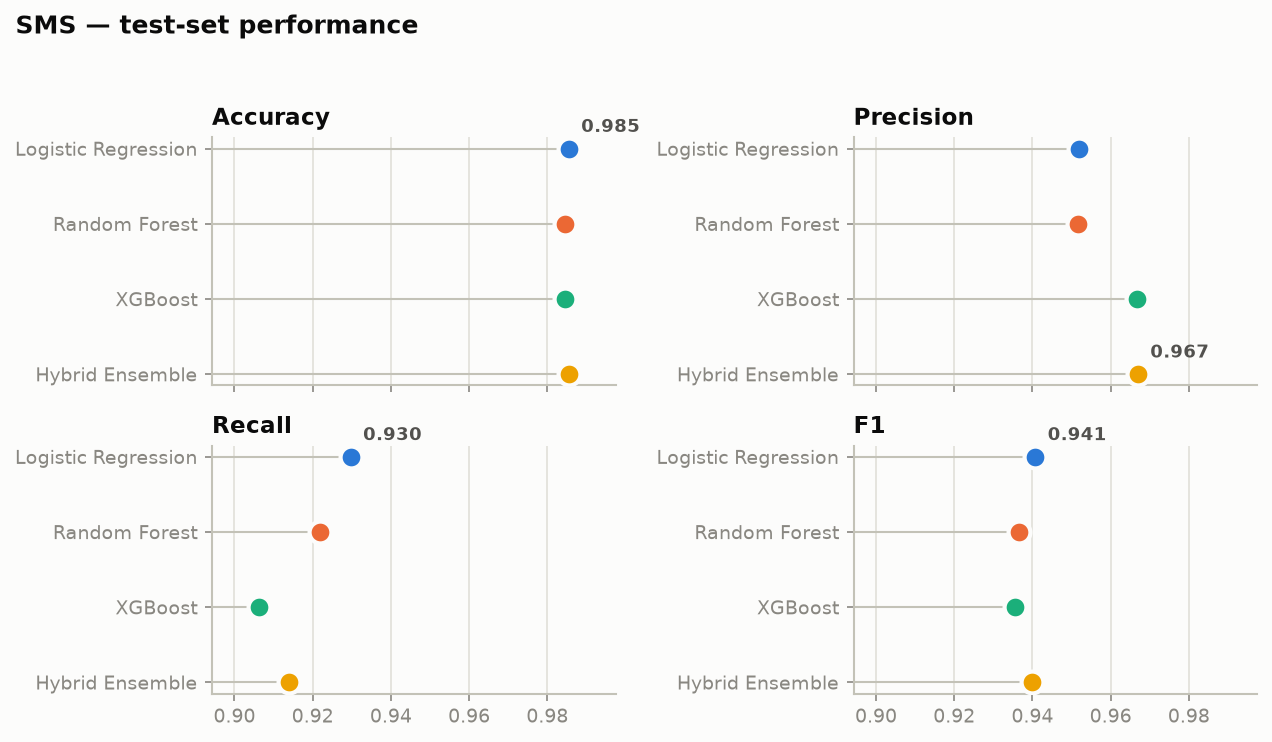

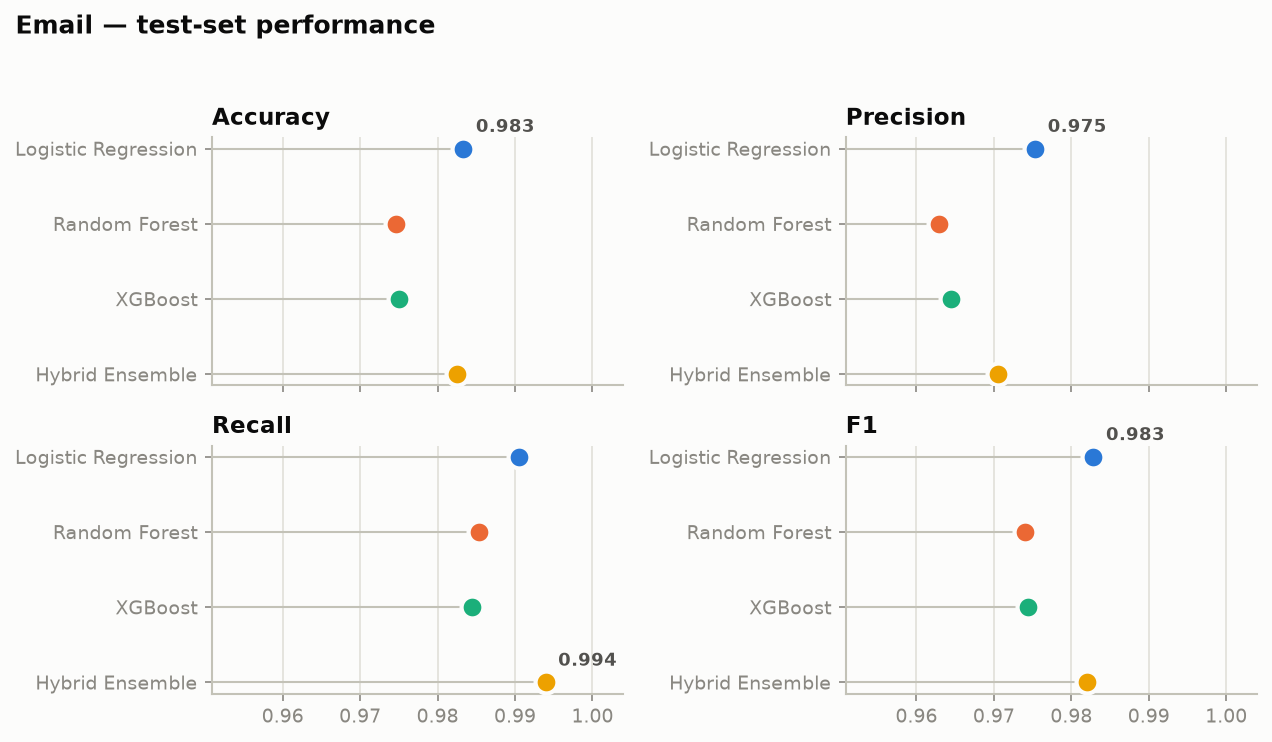

In [7]:
display(Image(filename=str(FIGURES_DIR / "sms_model_comparison.png"), width=820))
display(Image(filename=str(FIGURES_DIR / "email_model_comparison.png"), width=820))

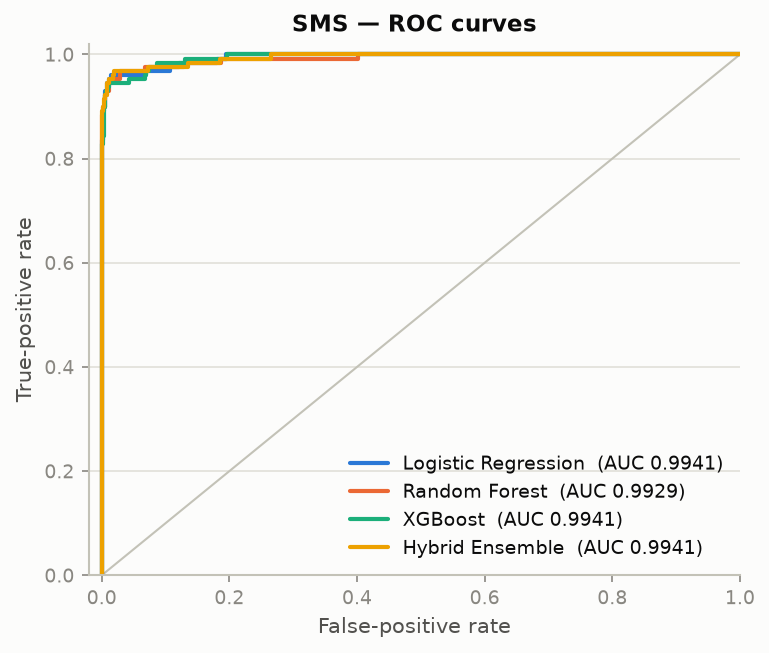

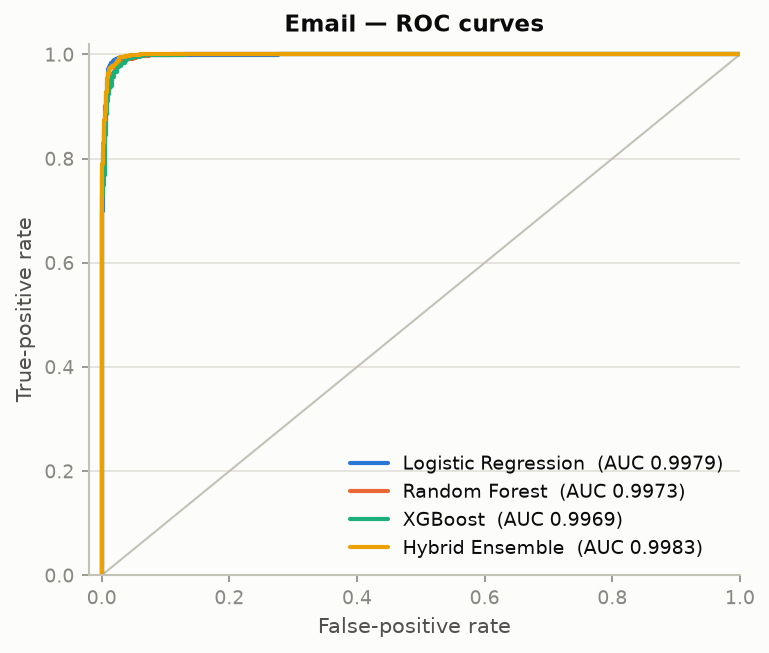

In [8]:
display(Image(filename=str(FIGURES_DIR / "sms_roc_curves.png"), width=520))
display(Image(filename=str(FIGURES_DIR / "email_roc_curves.png"), width=520))

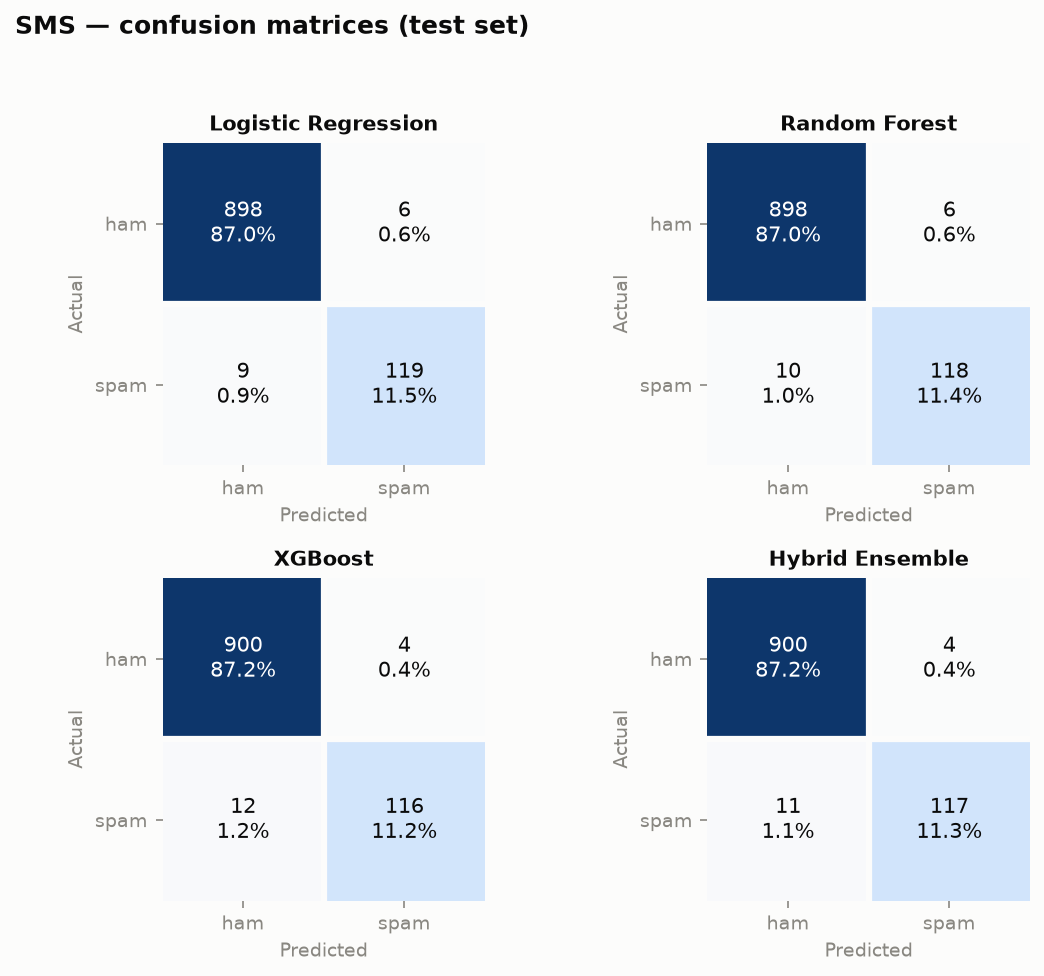

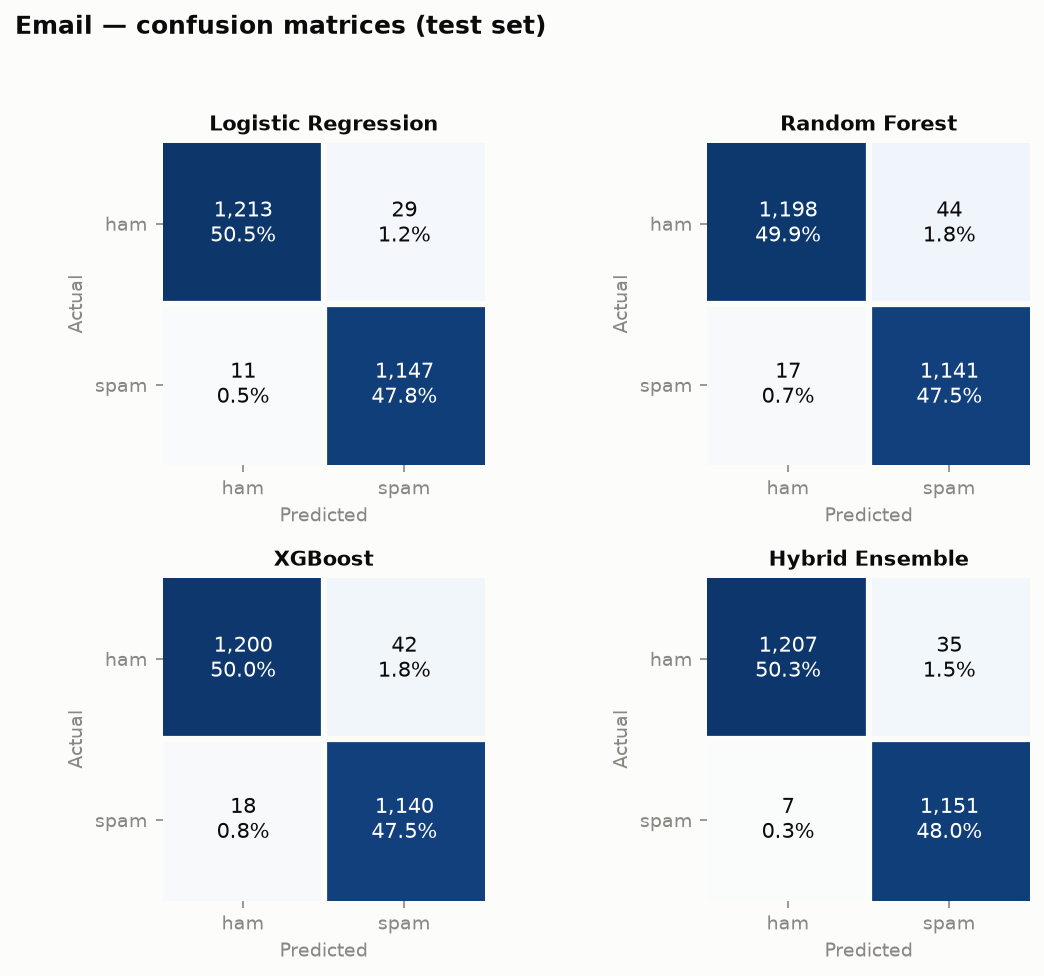

In [9]:
display(Image(filename=str(FIGURES_DIR / "sms_confusion_matrices.png"), width=680))
display(Image(filename=str(FIGURES_DIR / "email_confusion_matrices.png"), width=680))

## 5. Explainability analysis

### 5.1 Global — what did the models learn?

SHAP beeswarms over 800 held-out messages (exact TreeSHAP on the XGBoost component). Reading
guide: each dot is one message; x-position is the feature's push on the spam log-odds; colour is
the feature's value (red = high). Engineered stylometric features (`DIGIT_RATIO`,
`AVG_WORD_LEN`, `SPAM_KEYWORDS`) and structural tokens (`httpaddr`) dominate — spam is
recognised as much by *how* it is written as by *what* it says.

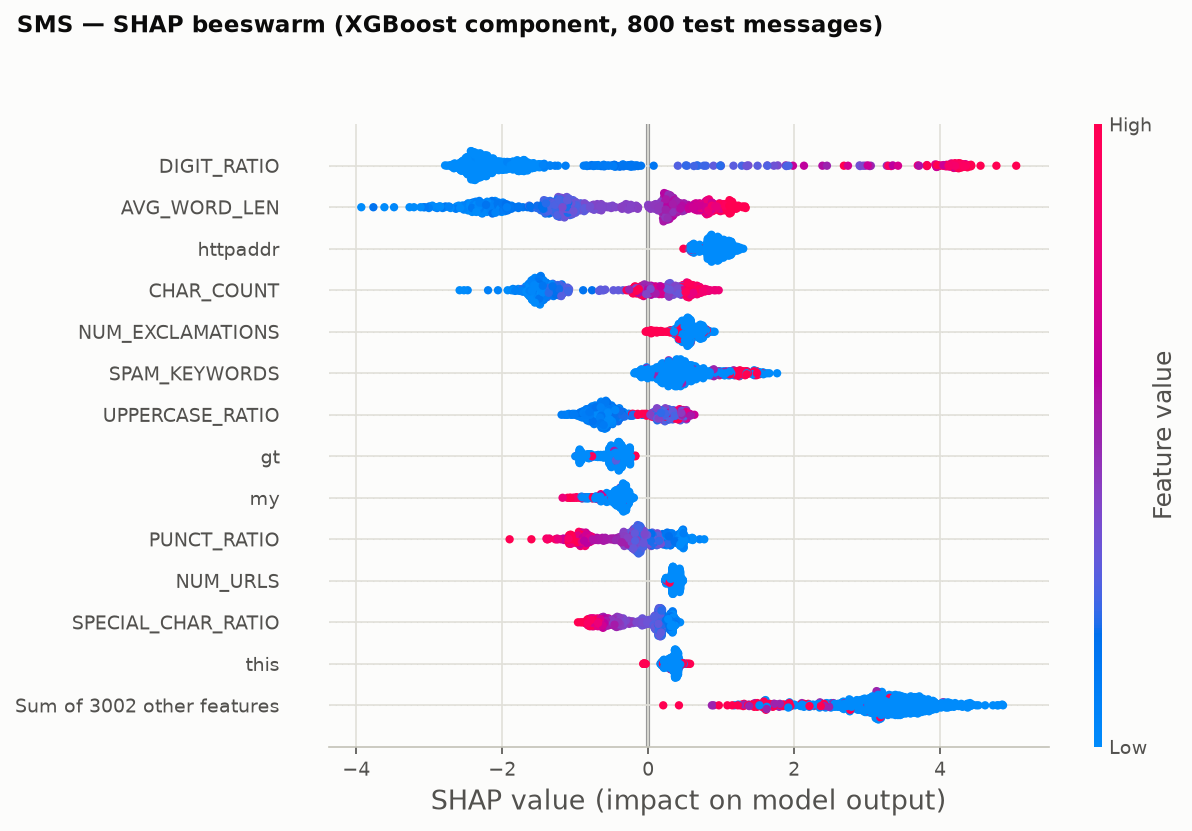

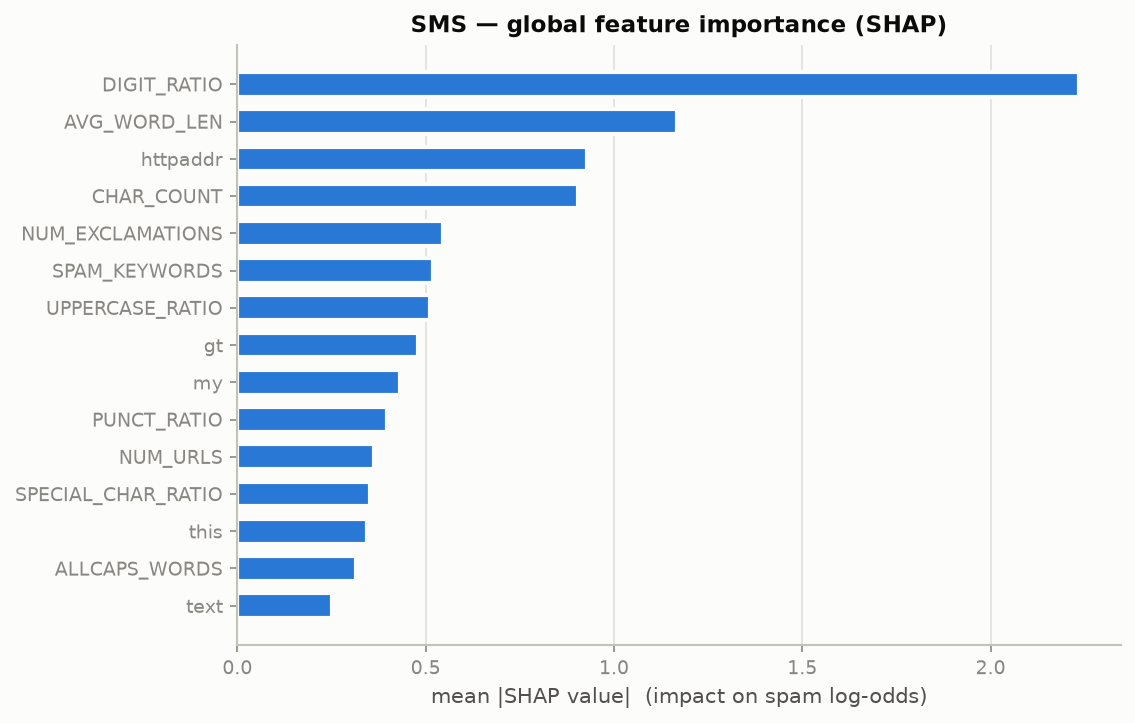

In [10]:
display(Image(filename=str(FIGURES_DIR / "sms_shap_beeswarm.png"), width=780))
display(Image(filename=str(FIGURES_DIR / "sms_shap_importance.png"), width=700))

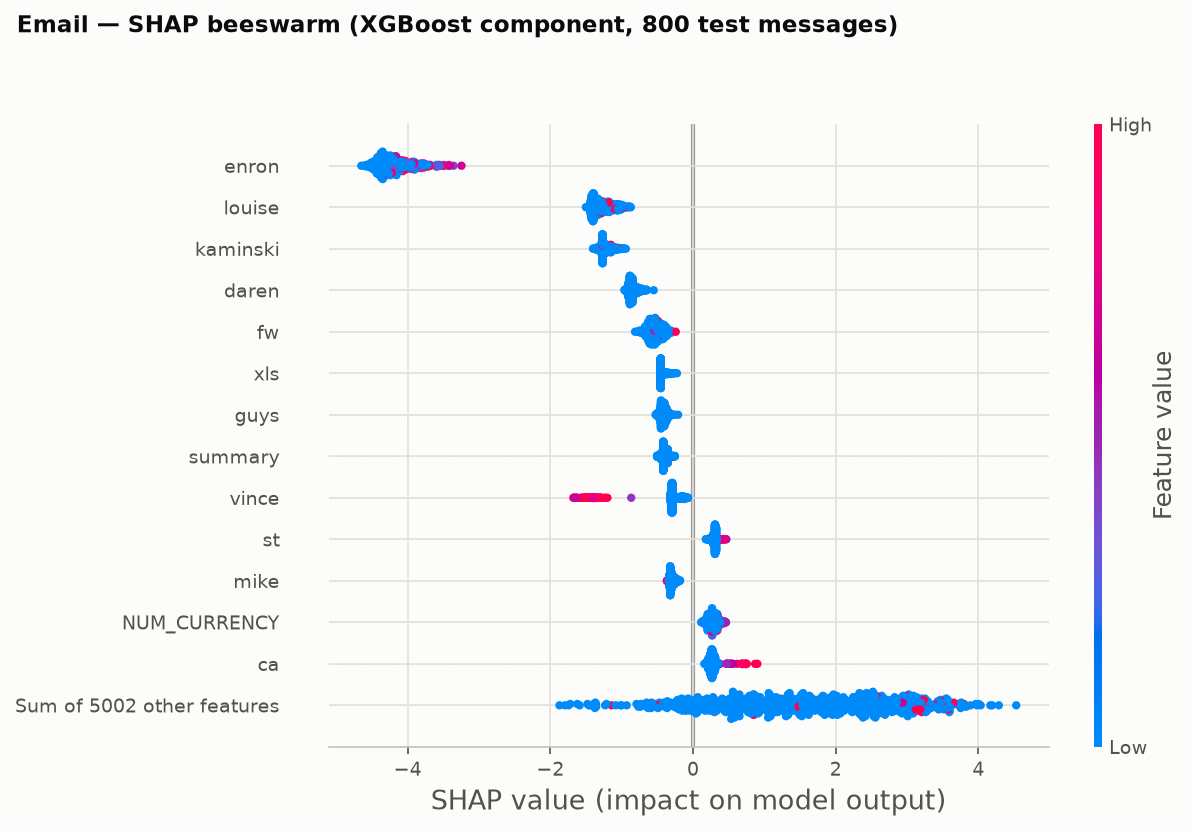

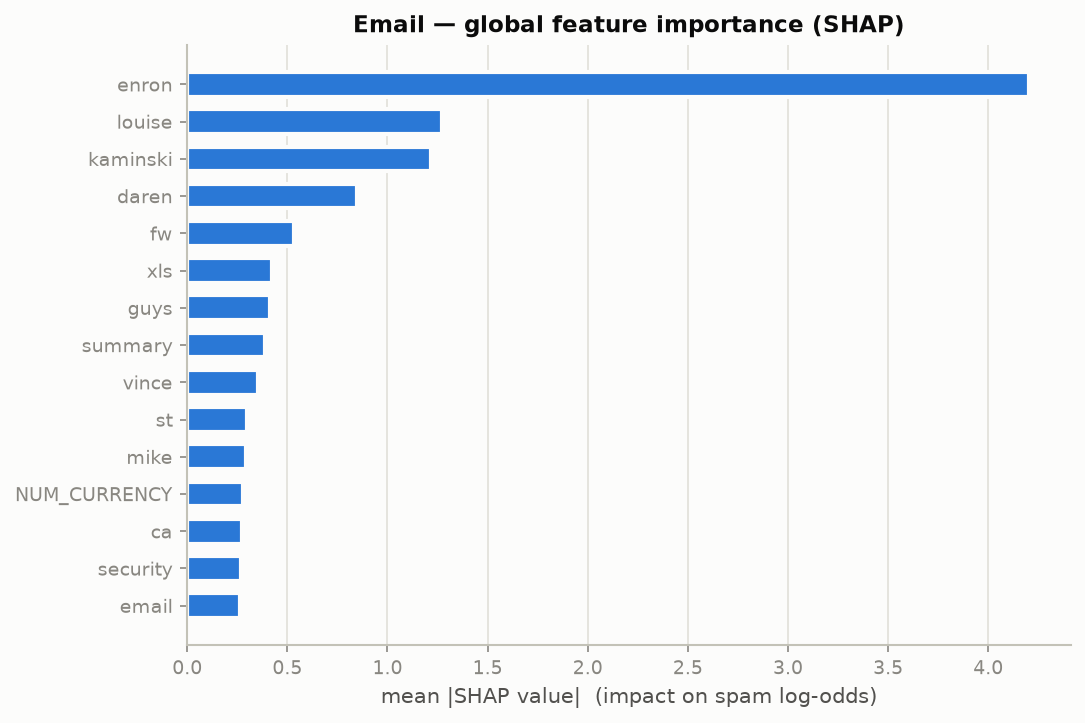

In [11]:
display(Image(filename=str(FIGURES_DIR / "email_shap_beeswarm.png"), width=780))
display(Image(filename=str(FIGURES_DIR / "email_shap_importance.png"), width=700))

### 5.2 Local — why was *this* message flagged?

A live demonstration on a scam SMS the models have never seen. **LIME** perturbs the raw message
~1 000 times (dropping words), re-scores every variant with the *full hybrid ensemble*, and fits
a local linear surrogate whose weights are per-word contributions.

In [12]:
from src.explain import lime_explain, build_shap_explainer, shap_explain_text

msg = ("URGENT! You have WON a £2,000 cash prize GUARANTEED. "
       "Call 09061701461 now or visit www.claim-your-prize.com to claim!")
det = detectors["sms"]
res = det.analyse(msg)
print(f"verdict: {res['label'].upper()}  |  ensemble spam probability {res['spam_probability']:.1%}")
print("per-model:", {k: f"{v:.1%}" for k, v in res["per_model"].items()})

exp = lime_explain(det, msg)
pd.DataFrame(exp.as_list(label=1), columns=["word", "LIME weight (+ = pushes spam)"])

/workspaces/spam_detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


verdict: SPAM  |  ensemble spam probability 99.6%
per-model: {'Logistic Regression': '100.0%', 'Random Forest': '98.7%', 'XGBoost': '100.0%'}


,word,LIME weight (+ = pushes spam)
0,09061701461,0.123493
1,000,0.060658
2,claim,0.053481
3,URGENT,0.046338
4,prize,0.044644
5,2,0.037891
6,GUARANTEED,0.037313
7,WON,0.035914
8,www,0.031197
9,your,0.024575


In [13]:
import matplotlib.pyplot as plt
from src.plotting import apply_style, style_axes, AXIS, SURFACE, CLASS_COLORS
apply_style()
pairs = exp.as_list(label=1)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh([w for w, _ in pairs], [v for _, v in pairs], height=0.6,
        color=[CLASS_COLORS["spam"] if v > 0 else CLASS_COLORS["ham"] for _, v in pairs],
        edgecolor=SURFACE, linewidth=2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlabel("LIME weight   ← pushes ham | pushes spam →")
ax.set_title("LIME — full-ensemble explanation of the scam SMS")
style_axes(ax, xgrid=True, ygrid=False)
plt.tight_layout(); plt.show()

**SHAP waterfall** for the same message — additive log-odds contributions of the XGBoost component, starting from the base rate E[f(x)] and ending at this message's score. The two views agree (phone number / digits, `URGENT`, prize vocabulary) while covering both scopes: LIME = whole ensemble, SHAP = exact attribution on the tree component.

In [14]:
import shap
sexp = shap_explain_text(det, build_shap_explainer(det), msg)
shap.plots.waterfall(sexp, max_display=12)

## 6. Discussion & conclusions

**Findings**

1. **The hybrid ensemble is consistently strong** — it never loses to its base learners on
   ROC-AUC and wins outright on Email, while precision-weighted voting keeps false alarms low
   (SMS precision ≈ 0.97 at ≈ 0.91 recall).
2. **Stylometry rivals vocabulary.** Across both modalities, engineered statistics
   (`DIGIT_RATIO`, `AVG_WORD_LEN`, `UPPERCASE_RATIO`, `SPAM_KEYWORDS`) sit at the top of the
   global SHAP ranking — a scam is betrayed by its *shape*.
3. **XAI as a debugging tool.** Global SHAP on the e-mail model ranks the token `enron` as a
   strong *ham* indicator: the corpus's legitimate mail is all Enron-internal, so the model
   partially learned the dataset, not the concept. This bias is invisible in accuracy tables and
   obvious in one beeswarm — the strongest argument for shipping explanations with predictions.

**Limitations & future work** — single-language (English) corpora from 2002–2012; the `enron`
bias implies cross-domain evaluation is needed; SHAP explains the boosted-tree component rather
than the whole ensemble (LIME covers that gap, at Monte-Carlo cost); future work: multilingual
corpora, calibration analysis, adversarial robustness (leet-speak obfuscation), and
counterfactual explanations.

**References**

1. Almeida, T.A. & Gómez Hidalgo, J.M. (2011). *SMS Spam Collection v.1*. UCI ML Repository.
2. Metsis, V., Androutsopoulos, I. & Paliouras, G. (2006). *Spam Filtering with Naive Bayes — Which Naive Bayes?* CEAS.
3. Ribeiro, M.T., Singh, S. & Guestrin, C. (2016). *"Why Should I Trust You?"* — LIME. KDD.
4. Lundberg, S.M. & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions* — SHAP. NeurIPS.
5. Chen, T. & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. KDD.
6. Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12.